# Les ouvertures répétées sur Lichess

**Projet Python pour la data science · Hadrien Fonrojet**

## Introduction

Après une victoire, les joueurs qui rejouent la même ouverture gagnent-ils plus souvent leur partie suivante ? Nous comparons le taux de victoire suivant une répétition à celui suivant un changement d’ouverture. La couleur, la cadence et l’écart de classement peuvent aussi influencer la comparaison.

**Rendu de démonstration.** Les séquences de parties, les scores et les comptes sont simulés. Les lignes d’ouverture proviennent du référentiel officiel Lichess. Les résultats enregistrés illustrent la méthode et portent uniquement sur cette simulation.

[Rendu de référence sur les Jeux olympiques](https://github.com/oldblindmole/Projet_Python_Data_Science_JO/blob/main/main.ipynb)

## Sommaire

1. Création et contrôle de la base
2. Statistiques descriptives et visualisation
3. Tests et modèle ajusté
4. Conclusion et limites


In [1]:
from pathlib import Path
import os
import sys
import subprocess

if not Path("config_projet.py").is_file() and Path("../config_projet.py").is_file():
    os.chdir("..")

if not Path("config_projet.py").is_file():
    root = Path("/content/ANALYSE-MARCHE-")
    if not root.exists():
        subprocess.run(["git", "clone", "https://github.com/Hadrienfonrojet/ANALYSE-MARCHE-.git", str(root)], check=True)
    os.chdir(root)
    subprocess.run([sys.executable, "-m", "pip", "install", "-r", "requirements.txt"], check=True)

sys.path.insert(0, str(Path.cwd()))

import numpy as np
import pandas as pd
from IPython.display import display, Image

import config_projet as cfg
from Nettoyage_donnees import clean_games
from Scripts_generation_data.Creation_Df_openings import creer_openings, identify_games
from Analyse_repetition_ouverture import analyser, descriptifs, preparer_cadres, taux_apres_victoire, tester_table


## I. Création et contrôle de la base

| Table | Origine | Unité |
|---|---|---|
| Référentiel | Cinq fichiers officiels Lichess, de a.tsv à e.tsv | Une ligne nommée |
| Parties | Simulation Python à graine fixée, avec des séquences de coups du référentiel | Une partie vue par un joueur |
| Transitions | Tri chronologique puis décalage par joueur | Deux parties observées |

La couleur et la cadence sont tirées au hasard. Chaque joueur retient ou change sa ligne d’ouverture entre deux parties. Le résultat simulé dépend de l’écart Elo et de la couleur. La répétition ne figure pas dans la formule de génération des résultats.


In [2]:
cfg.create_run()
reference = creer_openings()
rng = np.random.default_rng(73)
lines = reference.loc[reference.reference_ply.between(10, 20), "moves"].sample(6, random_state=73).tolist()

rows = []
for player in range(40):
    opening = int(rng.integers(len(lines)))
    for game in range(30):
        if rng.random() < .45:
            opening = int(rng.integers(len(lines)))
        rating, opponent = rng.integers(1200, 1850, size=2)
        color = rng.choice(["white", "black"])
        win_probability = .46 + .25 * np.tanh((rating - opponent) / 400)
        win_probability += .02 * (color == "white")
        result = rng.choice(["Win", "Draw", "Loss"], p=[win_probability, .08, .92 - win_probability])
        rows.append(dict(user_id=f"demo_{player}", game_id=f"demo_{player}_{game}",
                         timestamp_ms=1700000000000 + game * 180000,
                         result=result, rating=int(rating), opponent_rating=int(opponent),
                         format_partie=rng.choice(["blitz", "rapid"]), color=color,
                         moves=" ".join(lines[opening])))

raw = pd.DataFrame(rows)
parties = clean_games(identify_games(raw, reference, max_fullmoves=10, min_fullmoves=5))
print(f"Référentiel : {len(reference)} entrées")
print(f"Base : {len(parties)} lignes, {parties.user_id.nunique()} comptes simulés")
print(f"Doublons joueur-partie : {parties.duplicated(['user_id', 'game_id']).sum()}")
print("\nStatut de reconnaissance (fenêtre de 10 coups complets)")
print(parties.opening_identification_status.value_counts().to_string())
print("\nChamps utilisés et valeurs manquantes")
print(parties[["rating", "opponent_rating", "color", "format_partie", "opening_name", "result"]].isna().sum().to_string())


Référentiel : 3865 entrées
Base : 1200 lignes, 40 comptes simulés
Doublons joueur-partie : 0

Statut de reconnaissance (fenêtre de 10 coups complets)
opening_identification_status
identifiee    1200

Champs utilisés et valeurs manquantes
rating             0
opponent_rating    0
color              0
format_partie      0
opening_name       0
result             0


Le programme rejoue les coups et associe une position à une ouverture du référentiel. Dix coups complets représentent vingt demi-coups. Le nettoyage conserve les nulles dans l’ordre chronologique. Une transition avec une ouverture inconnue est exclue de la comparaison des répétitions.


## II. Statistiques descriptives et visualisation

Le score vaut 1 pour une victoire, 0,5 pour une nulle et 0 pour une défaite. Le taux de victoire compte uniquement les victoires. Nous affichons les effectifs avec les taux pour comparer les groupes.


In [3]:
print(descriptifs(parties).round(3).to_string(index=False))
print("\nRésultats par cadence")
print(pd.crosstab(parties.format_partie, parties.result).to_string())
cadres = preparer_cadres(parties)
immediat, taux = taux_apres_victoire(cadres["immediat"])
print("\nTransitions après victoire, cadre immédiat")
print(taux.round(3).to_string())


       variable    n     mean  median     std    min    max
         rating 1200 1519.082  1514.0 183.446 1201.0 1849.0
opponent_rating 1200 1519.472  1507.5 187.315 1200.0 1848.0
       elo_diff 1200   -0.390     3.0 260.345 -616.0  611.0
          score 1200    0.504     0.5   0.483    0.0    1.0

Résultats par cadence
result         Draw  Loss  Win
format_partie                 
blitz            40   264  288
rapid            41   291  276

Transitions après victoire, cadre immédiat
                  n  joueurs  victoires_suivantes  taux_victoire
repeat_opening                                                  
0.0             204       39                 97.0          0.475
1.0             340       40                155.0          0.456


## III. Tests et modèle ajusté

L’hypothèse nulle du χ² est l’indépendance entre la répétition et la victoire suivante, parmi les transitions après victoire. On calcule les effectifs attendus à partir des totaux de lignes et de colonnes. Fisher exact donne une seconde lecture du tableau 2 × 2 sous les hypothèses du test. Les valeurs p restent exploratoires, car un même joueur contribue plusieurs transitions.

Le cadre principal considère la partie suivante observée. Les deux comparaisons complémentaires exigent la même couleur, soit sur deux parties adjacentes, soit en recherchant la prochaine partie de cette couleur.


Tableau observé
win_next        0.0  1.0
repeat_opening          
0.0             107   97
1.0             185  155

Tableau attendu
win_next          0.0    1.0
repeat_opening              
0.0             109.5   94.5
1.0             182.5  157.5
Chi-deux = 0.197, ddl = 1, p = 0.6570
V de Cramér = 0.019, Fisher p = 0.6583

Comparaisons avec correction de Holm
                 cadre   n   chi2  p_chi2_holm  p_fisher_holm  min_expected
              immediat 544 0.1971       0.6570         0.6583       94.5000
 immediat_meme_couleur 269 1.1828       0.5536         0.6351       49.6506
prochaine_meme_couleur 522 2.3003       0.3880         0.4063      112.6169

Écart de taux et intervalle bootstrap par joueur
                 cadre  joueurs  difference  ci_low  ci_high  simulations_valides
              immediat       40     -0.0196 -0.0932   0.0529                 1000
 immediat_meme_couleur       40     -0.0677 -0.1856   0.0487                 1000
prochaine_meme_couleur       40     

Matplotlib is building the font cache; this may take a moment.


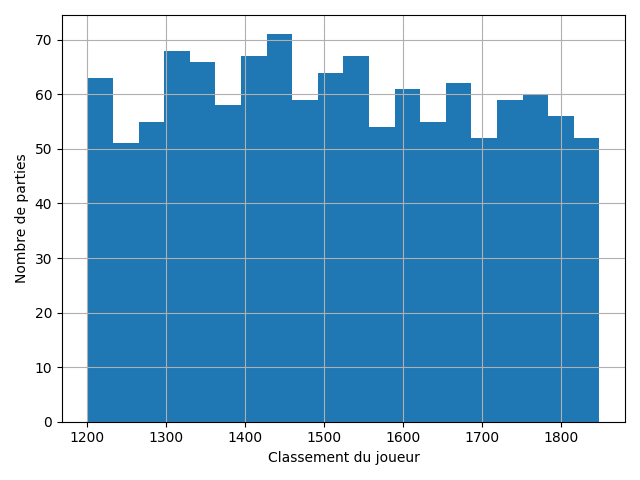

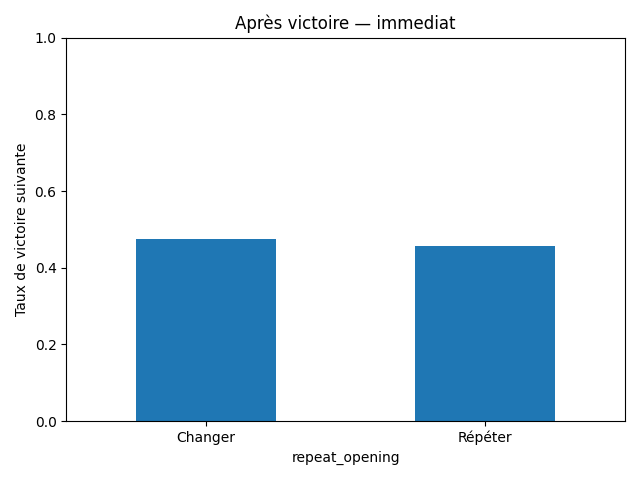

In [4]:
stat, observe, attendu = tester_table(immediat)
print("Tableau observé")
print(observe.to_string())
print("\nTableau attendu")
print(attendu.round(2).to_string())
print(f"Chi-deux = {stat['chi2']:.3f}, ddl = {stat['ddl']}, p = {stat['p_chi2']:.4f}")
print(f"V de Cramér = {stat['cramer_v']:.3f}, Fisher p = {stat['p_fisher']:.4f}")

resultats = analyser(parties, cfg.RESULTS_DIR)
cols = ["cadre", "n", "chi2", "p_chi2_holm", "p_fisher_holm", "min_expected"]
print("\nComparaisons avec correction de Holm")
print(resultats["tests"][cols].round(4).to_string(index=False))
print("\nÉcart de taux et intervalle bootstrap par joueur")
print(resultats["bootstrap"].round(4).to_string(index=False))
for filename in ["histogramme_rating.png", "taux_immediat.png"]:
    display(Image(filename=str(cfg.RESULTS_DIR / filename)))


La régression logistique compare les cotes de victoire à couleur, cadence et écart Elo fixés. Les erreurs-types sont regroupées par joueur. Le coefficient de répétition est exprimé en log-cotes. Son exponentielle est le rapport des cotes.


In [5]:
print(pd.Series(resultats["regression"]).to_string())
print(resultats["coefficients"].round(4).to_string(index=False))


n                                                        544
joueurs                                                   40
status                            estime_association_ajustee
formula    win_next ~ repeat_opening + elo_diff_100 + is_...
                      variable  coefficient_logit  odds_ratio  se_groupees  p_groupee  ci_coefficient_low  ci_coefficient_high
                     Intercept            -0.0610      0.9408       0.1742     0.7261             -0.4025               0.2804
C(format_partie_next)[T.rapid]            -0.2747      0.7598       0.1908     0.1499             -0.6487               0.0992
                repeat_opening            -0.1010      0.9039       0.1584     0.5236             -0.4114               0.2094
                  elo_diff_100             0.1565      1.1694       0.0309     0.0000              0.0959               0.2170
                 is_white_next             0.2325      1.2618       0.1187     0.0501             -0.0001               0

## IV. Conclusion et limites

Le protocole compare les taux observés, puis ajuste la comparaison sur la couleur, la cadence et l’écart de classement. Dans la simulation, le mécanisme de génération introduit un effet du classement et de la couleur. La fluctuation des taux entre les groupes reste possible.

Dans le cadre principal, le taux passe de 47,5 % après changement à 45,6 % après répétition, soit un écart d’environ −2,0 points. L’intervalle bootstrap à 95 % va d’environ −9,3 à +5,3 points. Le χ² a une valeur p de 0,657. Le rapport des cotes ajusté vaut environ 0,90. Ces résultats du cadre principal sont compatibles avec une association nulle dans la simulation.

Pour une étude empirique, il faut une collecte Lichess documentée et une chronologie aussi complète que possible. La comparaison restera observationnelle, notamment parce que les joueurs choisissent leurs ouvertures. Une même partie peut aussi apparaître des deux côtés si les deux joueurs figurent dans l’échantillon.

🟪 **Ton interprétation**

_Compare les taux et leur différence. Appuie ta lecture sur le tableau d’effectifs, l’intervalle du bootstrap et le résultat ajusté._
